# Grade Lab: evidence before confidence

A guided first ML project, built with AI assistance. We predict final mathematics grades and ask whether a trained model can beat simply repeating the earlier grade. Read the explanations, run the cells, and modify one experiment yourself.

## 1. Load and understand the data

Each row is a mathematics student record. G1 and G2 are earlier-period grades; G3 is the final grade (0–20). This public historical dataset comes from UCI, not from users of the app. Run this notebook from the project folder after installing requirements-dev.txt.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from grade_lab import load_data, split_data, run_experiments, FEATURES
df = load_data()
print(f"Rows: {len(df)}, columns: {len(df.columns)}")
df[["G1", "G2", "G3", "studytime", "failures"]].head()

Rows: 395, columns: 33


,G1,G2,G3,studytime,failures
0,5,6,6,2,0
1,5,5,6,2,0
2,7,8,10,2,3
3,15,14,15,3,0
4,6,10,10,2,0


## 2. Inspect before modeling

Check missing values and grade ranges. Keep zero grades: removing hard cases would change the question and could make the model look better than it is.

In [2]:
print("Missing cells:", int(df.isna().sum().sum()))
print("Zero final grades:", int((df.G3 == 0).sum()))
df[["G1", "G2", "G3"]].describe()

Missing cells: 0
Zero final grades: 38


,G1,G2,G3
count,395.000000,395.000000,395.000000
mean,10.908861,10.713924,10.415190
std,3.319195,3.761505,4.581443
min,3.000000,0.000000,0.000000
25%,8.000000,9.000000,8.000000
50%,11.000000,11.000000,11.000000
75%,13.000000,13.000000,14.000000
max,19.000000,19.000000,20.000000


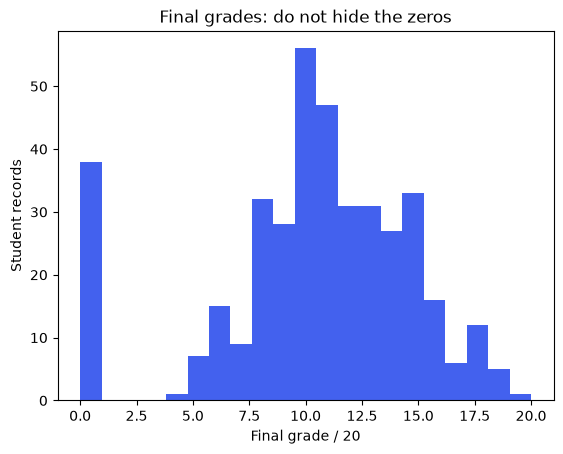

In [3]:
df.G3.plot.hist(bins=21, color="#4361ee", title="Final grades: do not hide the zeros")
plt.xlabel("Final grade / 20")
plt.ylabel("Student records")
plt.show()

## 3. Look for associations, not causes

Study-time categories are reported hours per week: 1 means <2, 2 means 2–5, 3 means 5–10, and 4 means >10. Category averages cannot establish what would happen if a particular student studied longer.

In [4]:
df.groupby("studytime").G3.agg(["count", "mean"]).round(2)

,count,mean
studytime,,
1,105,10.05
2,198,10.17
3,65,11.40
4,27,11.26


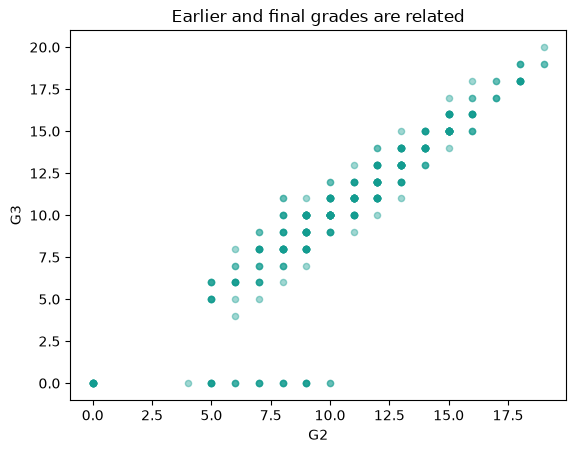

In [5]:
df.plot.scatter(x="G2", y="G3", alpha=.4, color="#139c90", title="Earlier and final grades are related")
plt.show()

## 4. Separate development from evaluation

The fixed 80/20 split makes the experiment reproducible. All model selection happens within the training portion. G3 is never an input. End-of-course absences are excluded because they might not be available at the intended prediction time.

In [6]:
train, test = split_data(df)
print(f"Training: {len(train)}; test: {len(test)}")
print("Overlapping row indexes:", len(set(train.index) & set(test.index)))
FEATURES

Training: 316; test: 79
Overlapping row indexes: 0


{'Earlier grades': ['G1', 'G2'],
 'Study context only': ['studytime', 'failures', 'traveltime'],
 'Grades + context': ['G1', 'G2', 'studytime', 'failures', 'traveltime']}

## 5. Compare useful baselines and models

Mean prediction, ridge regression, and a small tree compete. When G2 is available, we also try simply predicting G2. Five-fold cross-validation selects the lowest average MAE using training records only. Scaling for ridge is fitted inside each fold. Context-only models are retrospective because questionnaire timing is not established.

In [7]:
cv, results, models, predictions = run_experiments(df)
cv.round(3)

,experiment,model,cv_mae,cv_std
0,Earlier grades,Mean baseline,3.403,0.629
1,Earlier grades,Ridge regression,1.147,0.225
2,Earlier grades,Small decision tree,1.412,0.299
3,Earlier grades,Previous-grade baseline,0.953,0.245
4,Study context only,Mean baseline,3.403,0.629
5,Study context only,Ridge regression,3.261,0.510
6,Study context only,Small decision tree,3.289,0.443
7,Grades + context,Mean baseline,3.403,0.629
8,Grades + context,Ridge regression,1.145,0.259
9,Grades + context,Small decision tree,1.412,0.299


## 6. Evaluate only after selection

MAE is average absolute error in grade points. Lower is better. RMSE gives large mistakes more weight. R² compares squared error against predicting the test-target mean; it is not percentage accuracy.

In [8]:
results.round(3)

,experiment,selected_model,test_mae,test_rmse,test_r2
0,Earlier grades,Previous-grade baseline,1.000,2.072,0.791
1,Study context only,Ridge regression,3.499,4.400,0.056
2,Grades + context,Previous-grade baseline,1.000,2.072,0.791


### What actually happened?

The grade-based experiments select the previous-grade baseline. A simple rule wins this comparison. That is a valid ML result: added model complexity is not automatically useful. The study-context experiment has much larger held-out error. We should not reinterpret this as evidence that study habits do not matter causally.

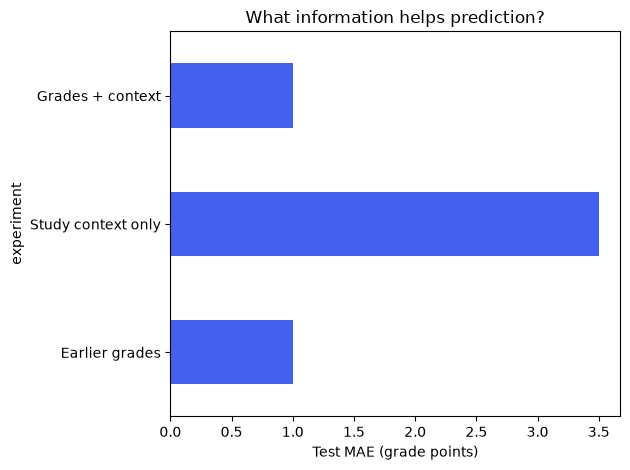

In [9]:
results.plot.barh(x="experiment", y="test_mae", legend=False, color="#4361ee", title="What information helps prediction?")
plt.xlabel("Test MAE (grade points)")
plt.tight_layout()
plt.show()

## 7. Audit errors

A one-point average error does not imply that every prediction is within one point. Inspect difficult cases without using them to retune the model.

In [10]:
audit = pd.DataFrame({"actual": test.G3, "predicted": predictions["Earlier grades"]})
audit["absolute_error"] = (audit.actual - audit.predicted).abs()
audit.sort_values("absolute_error", ascending=False).head(10)

,actual,predicted,absolute_error
334,0,9.0,9.0
140,0,9.0,9.0
316,0,8.0,8.0
168,0,7.0,7.0
33,12,10.0,2.0
393,10,12.0,2.0
78,10,8.0,2.0
375,10,8.0,2.0
157,10,8.0,2.0
45,6,8.0,2.0


In [11]:
audit.assign(zero_final_grade=audit.actual.eq(0)).groupby("zero_final_grade").absolute_error.agg(["count", "mean", "max"]).round(2)

,count,mean,max
zero_final_grade,,,
False,74,0.62,2.0
True,5,6.60,9.0


## 8. Your next learning step

Add a median baseline in grade_lab.py. Before running it, predict whether it will beat the mean baseline on MAE. Record your expectation and the actual result. The current test set is now inspected; do not tune repeatedly against it and call it untouched.

## Limits and credit

Historical data from two Portuguese schools cannot support universal student-level claims. Scenario curves are model responses, not causal advice. This demonstration must not determine admissions, grades, or access to support.

Dataset: Cortez, P. (2008), Student Performance, UCI, https://doi.org/10.24432/C5TG7T. CC BY 4.0. Original mathematics CSV unchanged; notebook outputs are derived analysis.